#  Explainable AI (XAI) for Photovoltaic Fault Classification using XGBoost

---

###  Overview & Motivation 
In mission-critical industrial applications such as **Photovoltaic (PV) Solar Power Systems**, high accuracy alone is not enough. Machine learning models like **XGBoost** are often treated as "black boxes" — leaving solar engineers, operators, and maintenance teams without clear visibility into **why** a string of panels is flagged as faulty.

**Explainable Artificial Intelligence (XAI)** bridges this trust gap by explaining model behavior at both global and local granularities:
1. **Model Trust & Reliability**: Validating that predictions obey physical laws ($P = I \times V$, temperature coefficients, and irradiance limits).
2. **Safety & Fast Root-Cause Analysis**: Distinguishing benign shading from hazardous conditions like **Short Circuits** or **Open Circuits** in real time.
3. **Actionable Operations**: Providing clear operational thresholds for SCADA alerts and preventive maintenance.

---

###  What This Notebook Covers 
1. **Data Pipeline & Multiclass XGBoost Setup**:
   - Multi-sensor electrical telemetry: Current ($I_1$), Voltage ($V_1$), Temperature ($T_1$), Power ($P_1$), Irradiance ($\text{Irr}$).
   - 5 Operational Classes: `Normal`, `Short Circuit`, `Open Circuit`, `Degradation`, `Shading`.
2. **Level 1: Native Tree-based Metrics**:
   - `Gain`, `Weight` (Frequency), and `Cover` comparisons.
3. **Level 2: Permutation Feature Importance (PFI)**:
   - Model-agnostic global validation on unseen test data.
4. **Level 3: SHAP (SHapley Additive exPlanations)**:
   - Game-theoretic TreeSHAP attribution.
   - Global multi-class Bar and Beeswarm Summary plots.
   - Feature Interaction & Dependence plots ($I_1$ vs $V_1$).
   - Local diagnostics: Waterfall & Force plots explaining individual fault incidents.
   - Decision plots tracing sequential probability shifts across multiple samples.
5. **Level 4: LIME (Local Interpretable Model-agnostic Explanations)**:
   - Local surrogate models with human-interpretable threshold rules (e.g., $V_1 \le 0.04\text{V}$).
6. **Level 5: Partial Dependence Plots (PDP) & ICE**:
   - 1D marginal effect curves and 2D interaction contour maps.
7. **Production Diagnostic Function & Synthesis**:
   - Real-time diagnostic inference function generating instant XAI reports for any live sensor packet.


In [1]:
# ==============================================================================
# Step 0: Imports, Environment Setup & Visual Configuration
# ==============================================================================
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Machine Learning & Metrics
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, 
    classification_report, 
    confusion_matrix, 
    roc_auc_score
)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

# Explainable AI (XAI) Frameworks
import shap
import lime
import lime.lime_tabular

# Visual styling setup
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print("=" * 65)
print("✅ All core data science and XAI libraries imported successfully!")
print(f"📦 XGBoost Version : {xgb.__version__}")
print(f"📦 SHAP Version    : {shap.__version__}")
print(f"📦 LIME Version    : {lime.__version__}")
print("=" * 65)

# Graceful compatibility patch for SHAP TreeExplainer with XGBoost >= 3.0 multiclass
try:
    from shap.explainers._tree import XGBTreeModelLoader
    _orig_loader_init = XGBTreeModelLoader.__init__
    def _safe_loader_init(self, model):
        try:
            _orig_loader_init(self, model)
        except ValueError as err:
            if "could not convert string to float" in str(err):
                import json
                import scipy.special
                booster_cfg = json.loads(model.save_config())
                learner = booster_cfg["learner"]
                l_param = learner["learner_model_param"]
                raw_base = l_param["base_score"]
                if raw_base.startswith("[") and raw_base.endswith("]"):
                    self.base_score = np.array([float(x.strip()) for x in raw_base[1:-1].split(",")])
                else:
                    self.base_score = float(raw_base)
            else:
                raise
    XGBTreeModelLoader.__init__ = _safe_loader_init
except Exception:
    pass


✅ All core data science and XAI libraries imported successfully!
📦 XGBoost Version : 3.2.0
📦 SHAP Version    : 0.49.1


AttributeError: module 'lime' has no attribute '__version__'

---
## 1. Data Loading & String Telemetry Inspection
### تحميل بيانات الحساسات الكهربائية للألواح وتجهيزها

We inspect electrical telemetry parameters recorded from photovoltaic strings:
* **$I_1$** (Current in Amperes)
* **$V_1$** (Voltage in Volts)
* **$T_1$** (Temperature in °C)
* **$P_1$** (Instantaneous Power in Watts, where $P = I \times V$)
* **$\text{Irr}$** (Solar Irradiance in $\text{W/m}^2$)

The target classes correspond to:
* `0`: **Normal** (Standard healthy operation)
* `1`: **Short Circuit** (Current spike, collapsed voltage $\approx 0\text{V}$)
* `2`: **Open Circuit** (Zero current $\approx 0\text{A}$, open-circuit voltage)
* `3`: **Degradation** (Elevated internal resistance, drop in efficiency)
* `4`: **Shading** (Reduced irradiance and current mismatch)


In [2]:
# ==============================================================================
# Step 1: Load Telemetry Dataset (with resilient path resolution)
# ==============================================================================
data_candidates = [
    "../data/PV_Diagnostic_Cleaned.csv",
    "data/PV_Diagnostic_Cleaned.csv",
    "../PV_Diagnostic_Cleaned.csv",
    "PV_Diagnostic_Cleaned.csv",
    "../data/PV_Diagnostic_Final_Labels.csv",
    "data/PV_Diagnostic_Final_Labels.csv"
]

data_path = None
for candidate in data_candidates:
    if os.path.exists(candidate):
        data_path = candidate
        break

if data_path:
    print(f"📂 Loading dataset from: {data_path}")
    df = pd.read_csv(data_path, sep=';' if ';' in open(data_path, errors='ignore').readline() else ',')
else:
    print("⚠️ Dataset file not found in default paths. Generating realistic synthetic PV telemetry for demonstration...")
    np.random.seed(42)
    n_samples = 25000
    irr = np.random.uniform(100, 1000, n_samples)
    temp = np.random.uniform(20, 55, n_samples)
    labels = np.random.choice([0, 1, 2, 3, 4], size=n_samples, p=[0.55, 0.05, 0.15, 0.15, 0.10])
    
    # Generate physics-aligned synthetic telemetry
    i1 = np.where(labels == 0, (irr / 1000.0) * 8.0 + np.random.normal(0, 0.1, n_samples),
         np.where(labels == 1, 8.5 + np.random.normal(0, 0.2, n_samples),
         np.where(labels == 2, np.random.uniform(0.00, 0.02, n_samples),
         np.where(labels == 3, (irr / 1000.0) * 5.2 + np.random.normal(0, 0.1, n_samples),
         (irr / 1000.0) * 2.5 + np.random.normal(0, 0.1, n_samples)))))
    
    v1 = np.where(labels == 0, 18.0 - (temp - 25) * 0.08 + np.random.normal(0, 0.2, n_samples),
         np.where(labels == 1, np.random.uniform(0.01, 0.08, n_samples),
         np.where(labels == 2, 21.5 - (temp - 25) * 0.05 + np.random.normal(0, 0.2, n_samples),
         np.where(labels == 3, 14.5 - (temp - 25) * 0.07 + np.random.normal(0, 0.2, n_samples),
         16.0 - (temp - 25) * 0.06 + np.random.normal(0, 0.2, n_samples)))))
    
    i1 = np.clip(i1, 0.0, 10.0)
    v1 = np.clip(v1, 0.0, 24.0)
    p1 = i1 * v1
    
    df = pd.DataFrame({
        "I1": i1, "V1": v1, "T1": temp, "P1": p1, "Irr": irr,
        "Label_Num_S1": labels + 1  # 1 to 5 mapping
    })

# Define features and target mapping
features = ["I1", "V1", "T1", "P1", "Irr"]
target_col = "Label_Num_S1"

# Prepare clean feature matrix and zero-indexed targets (0, 1, 2, 3, 4)
data = df[features + [target_col]].dropna().copy()
X = data[features]
y = data[target_col].astype(int)

# Map target to 0..4 if labels are 1..5
if y.min() == 1:
    y = y - 1

class_names = ["Normal", "Short Circuit", "Open Circuit", "Degradation", "Shading"]
class_dict = {i: name for i, name in enumerate(class_names)}

print(f"📊 Total processed samples: {len(X):,}")
print(f"📋 Features ({len(features)}): {features}")
print("\n🎯 Target Class Distribution:")
for class_id, count in y.value_counts().sort_index().items():
    print(f"   Class {class_id} ({class_names[class_id]:<14}): {count:>8,} samples ({count/len(y)*100:5.2f}%)")

X.head()


📂 Loading dataset from: ../data/PV_Diagnostic_Cleaned.csv
📊 Total processed samples: 226,175
📋 Features (5): ['I1', 'V1', 'T1', 'P1', 'Irr']

🎯 Target Class Distribution:
   Class 0 (Normal        ):   47,303 samples (20.91%)
   Class 1 (Short Circuit ):       53 samples ( 0.02%)
   Class 2 (Open Circuit  ):   58,171 samples (25.72%)
   Class 3 (Degradation   ):  103,885 samples (45.93%)
   Class 4 (Shading       ):   16,763 samples ( 7.41%)


,I1,V1,T1,P1,Irr
0,7.750000,0.036562,45.0,0.283359,978.0
1,1.167500,0.031875,45.0,0.037214,935.0
2,1.173125,0.025313,45.0,0.029695,935.0
3,1.169375,0.036562,45.0,0.042755,900.0
4,1.180625,0.034688,45.0,0.040953,900.0


---
## 2. Model Training & Evaluation
### تدريب نموذج XGBoost متعدد الفئات وتقييم دقة التنبؤ

We split the telemetry data into **stratified training (80%)** and **testing (20%)** sets.
If a pre-saved production model exists in the `models/` directory, we can load it directly; otherwise, we train an optimized `XGBClassifier` using the multi-class log-loss objective.


🔹 Training samples : 180,940
🔹 Testing samples  : 45,235

📦 Found pre-trained model checkpoint at: ../models/pv_xgboost_s1.pkl
✅ Pre-trained model extracted from package dict successfully!

🎯 Test Accuracy: 99.6551%


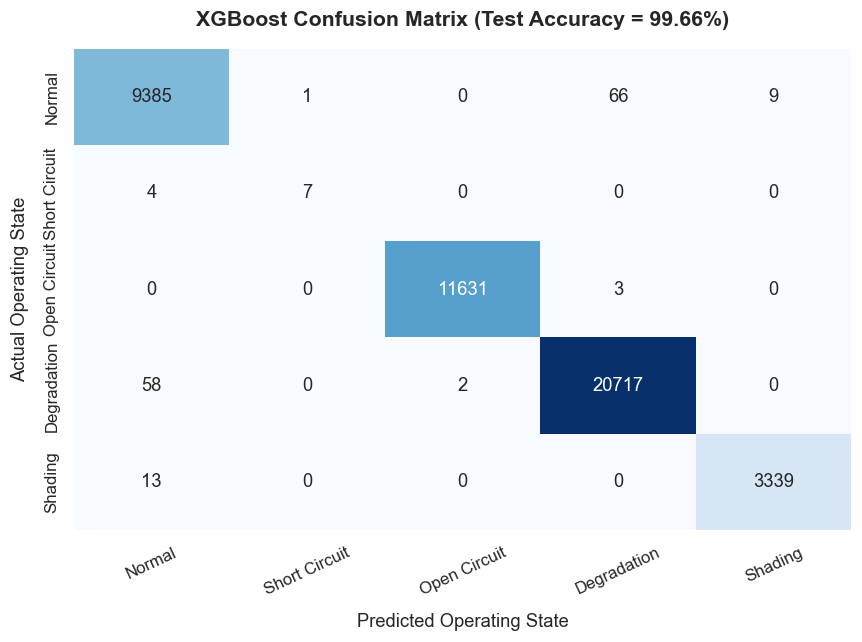


📄 Detailed Classification Report:
               precision    recall  f1-score   support

       Normal     0.9921    0.9920    0.9920      9461
Short Circuit     0.8750    0.6364    0.7368        11
 Open Circuit     0.9998    0.9997    0.9998     11634
  Degradation     0.9967    0.9971    0.9969     20777
      Shading     0.9973    0.9961    0.9967      3352

     accuracy                         0.9966     45235
    macro avg     0.9722    0.9243    0.9445     45235
 weighted avg     0.9965    0.9966    0.9965     45235



In [3]:
# ==============================================================================
# Step 2: Stratified Split & Model Training
# ==============================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print(f"🔹 Training samples : {len(X_train):,}")
print(f"🔹 Testing samples  : {len(X_test):,}")

# Check for pre-existing model checkpoint
model_candidates = [
    "../models/pv_xgboost_s1.pkl",
    "models/pv_xgboost_s1.pkl",
    "../models/xgboost_pv_multiclass.pkl",
    "models/xgboost_pv_multiclass.pkl"
]
saved_model_path = next((p for p in model_candidates if os.path.exists(p)), None)

if saved_model_path:
    print(f"\n📦 Found pre-trained model checkpoint at: {saved_model_path}")
    try:
        loaded_obj = joblib.load(saved_model_path)
        if isinstance(loaded_obj, dict):
            model = loaded_obj.get("model", loaded_obj)
            print("✅ Pre-trained model extracted from package dict successfully!")
        else:
            model = loaded_obj
            print("✅ Pre-trained model loaded successfully!")
    except Exception as e:
        print(f"⚠️ Could not load checkpoint ({e}). Training new XGBoost classifier...")
        model = None
else:
    model = None

if model is None:
    print("\n⚡ Training new XGBoost Classifier with Multi-Softprob objective...")
    model = XGBClassifier(
        n_estimators=250,
        max_depth=5,
        learning_rate=0.06,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="multi:softprob",
        num_class=len(class_names),
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)
    print("✅ Training complete!")

# Evaluate performance on test set
y_pred = model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)
print(f"\n🎯 Test Accuracy: {test_acc:.4%}")

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, 
    annot=True, 
    fmt="d", 
    cmap="Blues", 
    xticklabels=class_names, 
    yticklabels=class_names,
    cbar=False
)
plt.title(f"XGBoost Confusion Matrix (Test Accuracy = {test_acc:.2%})", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Predicted Operating State", fontsize=12, labelpad=10)
plt.ylabel("Actual Operating State", fontsize=12, labelpad=10)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

print("\n📄 Detailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))


---
## 3. Level 1: Native XGBoost Feature Importance
### أهمية الخصائص المضمنة داخل أشجار القرار (Gain vs. Weight vs. Cover)

Gradient Boosted Decision Trees natively compute three distinct importance metrics:

1. **Weight / Frequency**: The raw count of times a feature was selected to split branches across all trees.
   - *Limitation*: Can unfairly favor continuous features with wide numerical ranges simply because they offer more potential split thresholds.
2. **Gain (Most Critical)**: The average reduction in loss (gain in branch purity) achieved when splitting on that feature.
   - *Key Advantage*: Directly reflects how much predictive information the feature delivers.
3. **Cover**: The relative number of training samples passing through splits that utilize this feature.

Below, we compare all three metrics side-by-side to expose the difference between **split frequency** and **predictive power**.


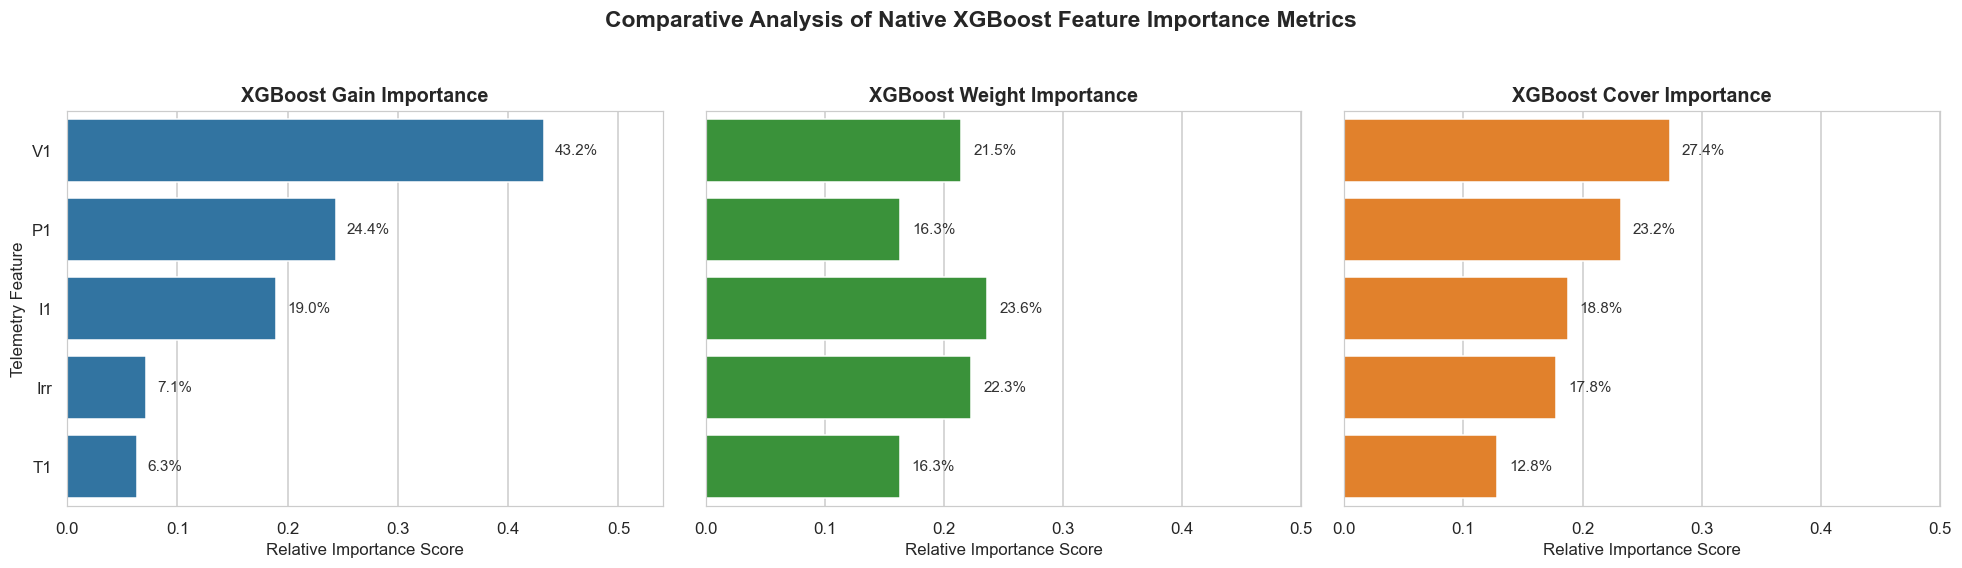

📋 Ranked Features by Gain (Predictive Quality):
   1. V1     | Gain:     219.63 (43.2%) | Weight: 7453 splits
   2. P1     | Gain:     123.93 (24.4%) | Weight: 5661 splits
   3. I1     | Gain:      96.43 (19.0%) | Weight: 8208 splits
   4. Irr    | Gain:      36.29 ( 7.1%) | Weight: 7740 splits
   5. T1     | Gain:      31.98 ( 6.3%) | Weight: 5657 splits


In [4]:
# ==============================================================================
# Step 3: Compute & Compare Native XGBoost Importance Metrics
# ==============================================================================
booster = model.get_booster()

# Extract dictionaries for all 3 metrics
gain_scores = booster.get_score(importance_type="gain")
weight_scores = booster.get_score(importance_type="weight")
cover_scores = booster.get_score(importance_type="cover")

# Align with all feature names (defaulting missing to 0)
importance_df = pd.DataFrame({
    "Feature": features,
    "Gain": [gain_scores.get(f, 0.0) for f in features],
    "Weight": [weight_scores.get(f, 0.0) for f in features],
    "Cover": [cover_scores.get(f, 0.0) for f in features]
})

# Normalize for comparative visualization
for col in ["Gain", "Weight", "Cover"]:
    total = importance_df[col].sum()
    importance_df[f"{col}_Normalized"] = (importance_df[col] / total) if total > 0 else 0

# Sort by Gain (the most reliable metric)
importance_df = importance_df.sort_values(by="Gain", ascending=False).reset_index(drop=True)

# Plot side-by-side comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
palette = ["#1f77b4", "#2ca02c", "#ff7f0e"]

for idx, (metric, color) in enumerate(zip(["Gain", "Weight", "Cover"], palette)):
    sns.barplot(
        data=importance_df.sort_values(by=metric, ascending=False),
        x=f"{metric}_Normalized",
        y="Feature",
        ax=axes[idx],
        color=color
    )
    axes[idx].set_title(f"XGBoost {metric} Importance", fontsize=13, fontweight='bold')
    axes[idx].set_xlabel("Relative Importance Score", fontsize=11)
    axes[idx].set_ylabel("" if idx > 0 else "Telemetry Feature", fontsize=11)
    
    # Annotate bar percentages
    for p in axes[idx].patches:
        width = p.get_width()
        axes[idx].annotate(
            f"{width:.1%}",
            (width + 0.01, p.get_y() + p.get_height() / 2),
            ha='left', va='center', fontsize=10, color='#333333'
        )
    axes[idx].set_xlim(0, max(importance_df[f"{metric}_Normalized"].max() * 1.25, 0.5))

plt.suptitle("Comparative Analysis of Native XGBoost Feature Importance Metrics", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

print("📋 Ranked Features by Gain (Predictive Quality):")
for rank, row in importance_df.iterrows():
    print(f"   {rank+1}. {row['Feature']:<6} | Gain: {row['Gain']:>10.2f} ({row['Gain_Normalized']:5.1%}) | Weight: {int(row['Weight']):>4} splits")


---
## 4. Level 2: Permutation Feature Importance (PFI)
### أهمية الخصائص عبر التبديل العشوائي (Model-Agnostic Global Evaluation)

Permutation Feature Importance is a **model-agnostic** global technique that tests feature importance by breaking the association between a specific feature and the target:

1. Record baseline test accuracy.
2. For each feature, shuffle (permute) its column values randomly among the test samples.
3. Measure the drop in performance on the permuted set.
4. **Conclusion**: If shuffling a feature causes a massive drop in accuracy, the model depends heavily on it.

Unlike native tree gain, PFI is evaluated **on unseen test samples**, ensuring it is immune to tree-depth or splitting artifacts.


⏳ Running Permutation Importance (10 repeats) across 5,000 test samples...


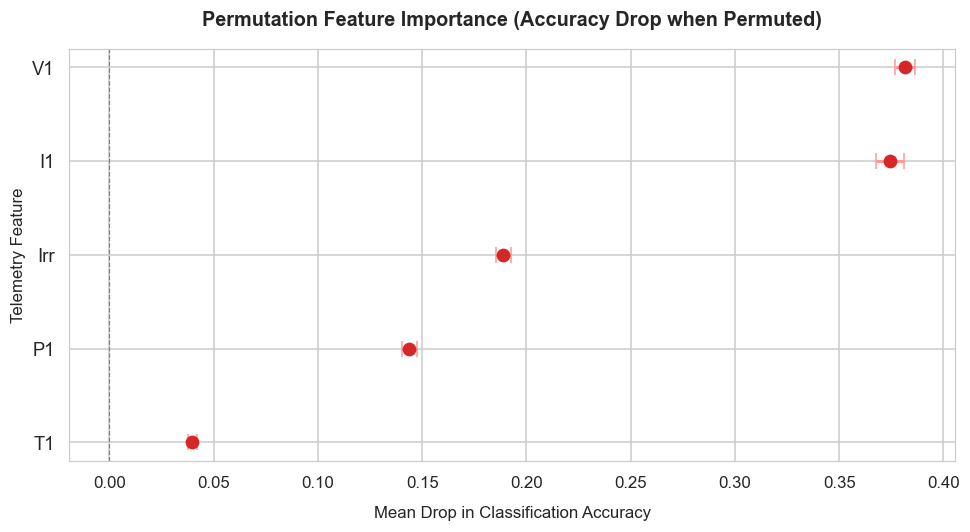

📋 Permutation Importance Rankings:
   1. V1     : Accuracy Drop = 0.3817 ± 0.0047
   2. I1     : Accuracy Drop = 0.3743 ± 0.0068
   3. Irr    : Accuracy Drop = 0.1889 ± 0.0036
   4. P1     : Accuracy Drop = 0.1439 ± 0.0034
   5. T1     : Accuracy Drop = 0.0396 ± 0.0022


In [5]:
# ==============================================================================
# Step 4: Permutation Feature Importance on Test Set
# ==============================================================================
# Use a representative test sample for high speed and robustness
pfi_sample_size = min(5000, len(X_test))
X_pfi = X_test.iloc[:pfi_sample_size]
y_pfi = y_test.iloc[:pfi_sample_size]

print(f"⏳ Running Permutation Importance (10 repeats) across {pfi_sample_size:,} test samples...")
pfi_results = permutation_importance(
    model, 
    X_pfi, 
    y_pfi, 
    n_repeats=10, 
    random_state=42, 
    scoring="accuracy",
    n_jobs=-1
)

pfi_df = pd.DataFrame({
    "Feature": features,
    "Mean_Drop": pfi_results.importances_mean,
    "Std": pfi_results.importances_std
}).sort_values(by="Mean_Drop", ascending=False).reset_index(drop=True)

# Visualize Permutation Importance
plt.figure(figsize=(9, 5))
plt.errorbar(
    pfi_df["Mean_Drop"], 
    range(len(pfi_df)), 
    xerr=pfi_df["Std"], 
    fmt='o', 
    color='#d62728', 
    ecolor='#ff9896', 
    elinewidth=2, 
    capsize=5, 
    markersize=8
)
plt.yticks(range(len(pfi_df)), pfi_df["Feature"], fontsize=12)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title("Permutation Feature Importance (Accuracy Drop when Permuted)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Mean Drop in Classification Accuracy", fontsize=11, labelpad=10)
plt.ylabel("Telemetry Feature", fontsize=11)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("📋 Permutation Importance Rankings:")
for rank, row in pfi_df.iterrows():
    print(f"   {rank+1}. {row['Feature']:<6} : Accuracy Drop = {row['Mean_Drop']:.4f} ± {row['Std']:.4f}")


---
## 5. Level 3: SHAP (SHapley Additive exPlanations)
### التفسير الرياضي المعتمد على نظرية الألعاب التعاونية (Game-Theoretic Attribution)

**SHAP** is widely recognized as the gold standard in Explainable AI. Derived from cooperative game theory (Lloyd Shapley, 1953), it assigns each feature a payout (Shapley value) representing its marginal contribution to the prediction across all possible feature coalitions.

Key mathematical properties:
* **Efficiency (Local Accuracy)**: The sum of SHAP values across all features plus the base expected value equals the model output:
  $$\sum_{j=1}^{M} \phi_j(x) + E[f(x)] = f(x)$$
* **Missingness**: A feature with no impact receives $\phi_j = 0$.
* **Consistency**: If a model changes such that a feature's marginal contribution increases or stays the same, its Shapley value cannot decrease.

For tree models, **TreeSHAP** computes exact Shapley values in polynomial time $\mathcal{O}(T \cdot L \cdot D^2)$ rather than exponential time!


In [6]:
# ==============================================================================
# Step 5: Compute TreeSHAP Values
# ==============================================================================
# TreeExplainer is specifically optimized for XGBoost
explainer = shap.TreeExplainer(model)

# Subsample test set for fast, smooth visualization (1,000 samples is ideal)
shap_sample_size = min(1000, len(X_test))
X_shap = X_test.iloc[:shap_sample_size].copy()
y_shap = y_test.iloc[:shap_sample_size].copy()

print(f"⏳ Computing TreeSHAP values for {len(X_shap):,} multi-sensor telemetry samples...")
shap_values = explainer(X_shap)

print("✅ SHAP computation complete!")
print(f"🔹 SHAP values matrix shape : {shap_values.values.shape}")
print(f"   └── (Samples: {shap_values.values.shape[0]}, Features: {shap_values.values.shape[1]}, Classes: {shap_values.values.shape[2]})")
print(f"🔹 Base values (Expected model outputs per class):")
for c_idx, c_name in enumerate(class_names):
    base_val = explainer.expected_value[c_idx] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value
    print(f"   └── Class {c_idx} ({c_name:<14}): {base_val:.4f}")


⏳ Computing TreeSHAP values for 1,000 multi-sensor telemetry samples...
✅ SHAP computation complete!
🔹 SHAP values matrix shape : (1000, 5, 5)
   └── (Samples: 1000, Features: 5, Classes: 5)
🔹 Base values (Expected model outputs per class):
   └── Class 0 (Normal        ): 1.5823
   └── Class 1 (Short Circuit ): -4.4808
   └── Class 2 (Open Circuit  ): -0.6117
   └── Class 3 (Degradation   ): 2.2346
   └── Class 4 (Shading       ): -0.1775


---
### 5.1 Global SHAP: Multi-Class Bar Plot & Beeswarm Summary Plots
#### ملخص تأثير الخصائص واتجاهها على جميع حالات التشغيل

* **Multi-Class Bar Plot**: Shows which features dominate classification decisions across each individual operating state.
* **Beeswarm Plot**: Plots every individual sample as a dot.
  * **X-axis position**: The SHAP value (impact on model log-odds). Dots to the right push toward the fault; dots to the left push away.
  * **Color**: Feature value (**Red = High**, **Blue = Low**).
  * Example: In **Short Circuit**, high current ($I_1$ red) and very low voltage ($V_1$ blue) both push the prediction strongly to the right!


<Figure size 1100x660 with 0 Axes>

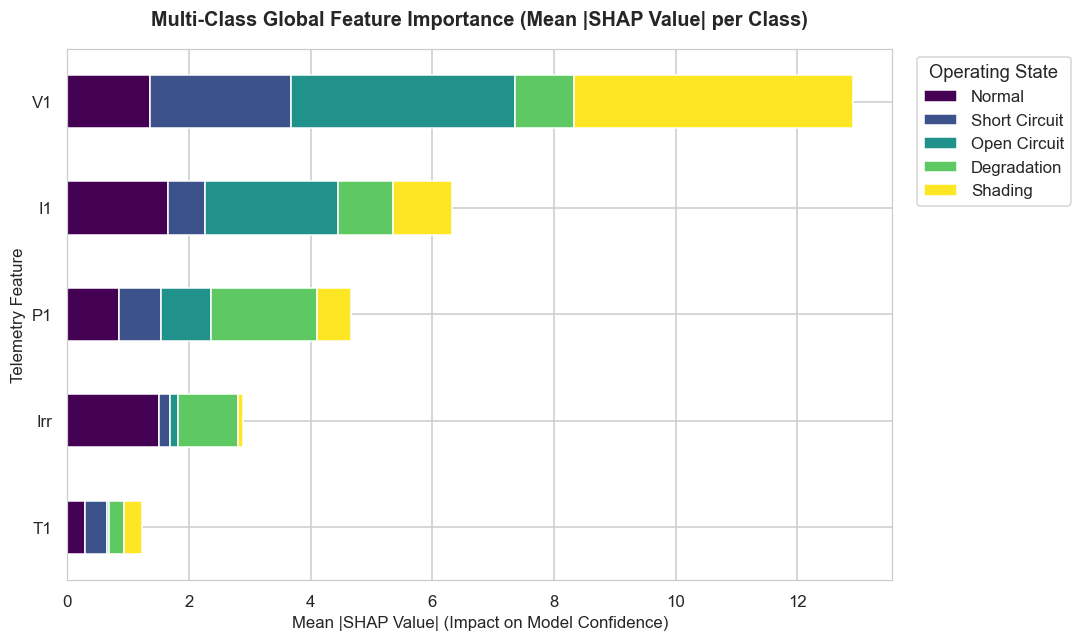

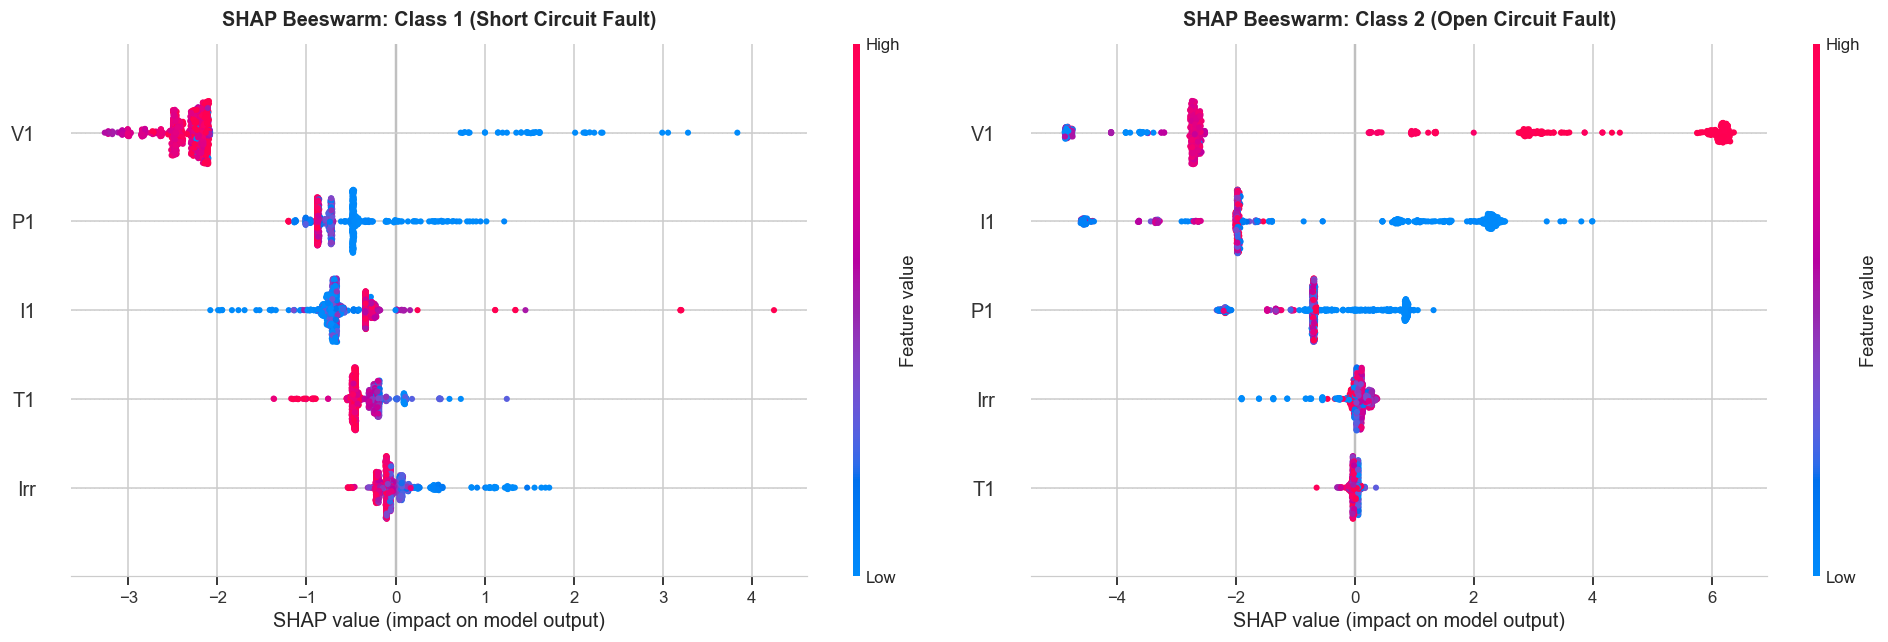

In [7]:
# ==============================================================================
# Step 5.1: Global SHAP Summary Visualizations
# ==============================================================================

# 1. Multi-Class Feature Importance Bar Plot
plt.figure(figsize=(10, 6))
# Calculate mean absolute SHAP values per class
mean_abs_shap = np.mean(np.abs(shap_values.values), axis=0) # shape: (n_features, n_classes)
shap_bar_df = pd.DataFrame(mean_abs_shap, index=features, columns=class_names)
shap_bar_df["Total"] = shap_bar_df.sum(axis=1)
shap_bar_df = shap_bar_df.sort_values(by="Total", ascending=True)
shap_bar_df.drop(columns="Total").plot(kind='barh', stacked=True, figsize=(10, 6), colormap="viridis")

plt.title("Multi-Class Global Feature Importance (Mean |SHAP Value| per Class)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Mean |SHAP Value| (Impact on Model Confidence)", fontsize=11)
plt.ylabel("Telemetry Feature", fontsize=11)
plt.legend(title="Operating State", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 2. Beeswarm Plots for Critical Fault Modes
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Class 1: Short Circuit
plt.sca(axes[0])
shap.plots.beeswarm(
    shap_values[:, :, 1], 
    max_display=5, 
    show=False,
    plot_size=None
)
axes[0].set_title("SHAP Beeswarm: Class 1 (Short Circuit Fault)", fontsize=13, fontweight='bold', pad=12)

# Class 2: Open Circuit
plt.sca(axes[1])
shap.plots.beeswarm(
    shap_values[:, :, 2], 
    max_display=5, 
    show=False,
    plot_size=None
)
axes[1].set_title("SHAP Beeswarm: Class 2 (Open Circuit Fault)", fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()


---
### 5.2 SHAP Dependence & Feature Interaction Plots
#### تحليل التفاعل اللاخطي بين متغيرات التيار والجهد والإشعاع الشمسي

SHAP dependence plots show how a feature's value affects its SHAP attribution, automatically revealing **non-linear physics thresholds** and **cross-feature interactions**:
* As Current $I_1$ surpasses normal limits, does its contribution to Short Circuit spike exponentially?
* How does Voltage $V_1$ interact with Current $I_1$ during fault detection?


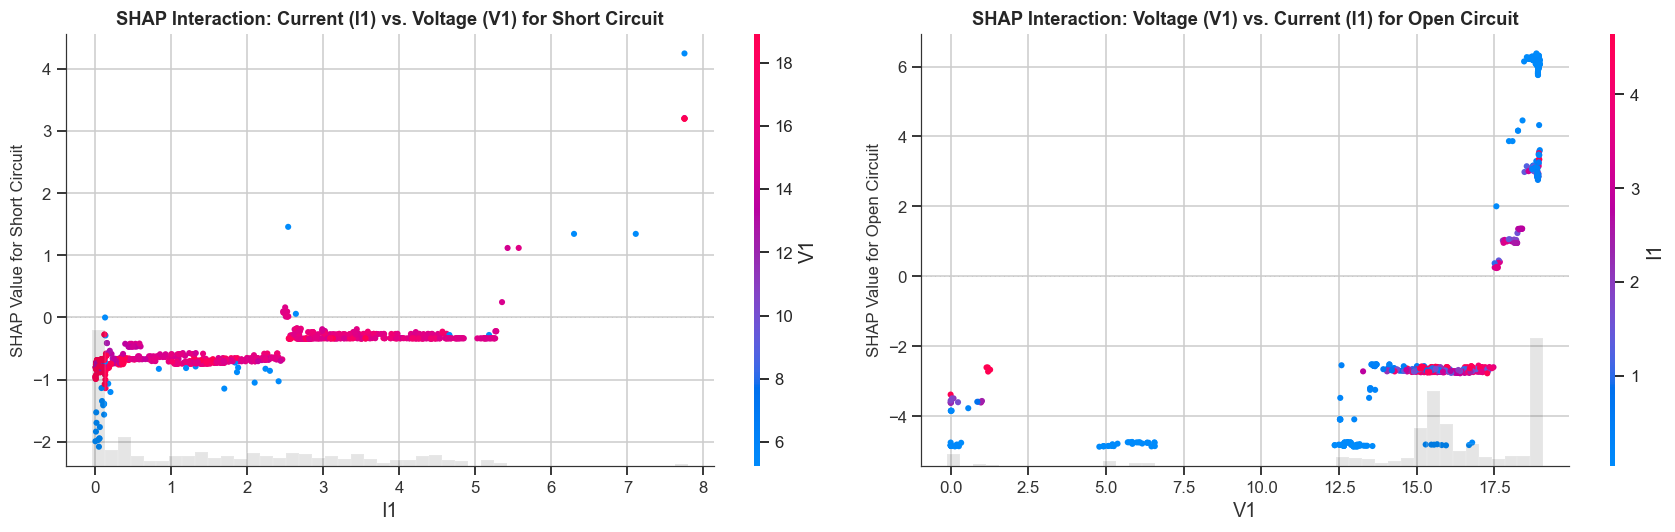

In [8]:
# ==============================================================================
# Step 5.2: SHAP Dependence & Feature Interaction Analysis
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Current (I1) vs SHAP Value for Short Circuit, colored by Voltage (V1)
plt.sca(axes[0])
shap.plots.scatter(
    shap_values[:, "I1", 1], 
    color=shap_values[:, "V1", 1],
    ax=axes[0],
    show=False
)
axes[0].set_title("SHAP Interaction: Current (I1) vs. Voltage (V1) for Short Circuit", fontsize=12, fontweight='bold')
axes[0].set_ylabel("SHAP Value for Short Circuit", fontsize=11)

# 2. Voltage (V1) vs SHAP Value for Open Circuit, colored by Current (I1)
plt.sca(axes[1])
shap.plots.scatter(
    shap_values[:, "V1", 2], 
    color=shap_values[:, "I1", 2],
    ax=axes[1],
    show=False
)
axes[1].set_title("SHAP Interaction: Voltage (V1) vs. Current (I1) for Open Circuit", fontsize=12, fontweight='bold')
axes[1].set_ylabel("SHAP Value for Open Circuit", fontsize=11)

plt.tight_layout()
plt.show()


---
### 5.3 Local SHAP Instance Explanations (Waterfall & Force Plots)
#### تشخيص الحالات الفردية: لماذا صنف النموذج هذا القياس بالذات كعطل خطير؟

Local explanations decompose a **single instantaneous telemetry packet** into individual feature contributions:
* **$E[f(x)]$ (Base Value)**: The model's baseline average prediction across all training data.
* **$f(x)$**: The final predicted output for this specific reading.
* **Red arrows ($+$)**: Features pushing the probability higher towards this fault.
* **Blue arrows ($-$)**: Features pushing the probability lower away from this fault.


🔍 Scenario A: Diagnosing Short Circuit Case (Sample #64)
   Sensor Readings: {'I1': 2.538125, 'V1': 0.9815625, 'T1': 33.55904325950045, 'P1': 2.4913283203125, 'Irr': 237.34068124622823}
   Model Prediction: Normal (Confidence = 53.82%)



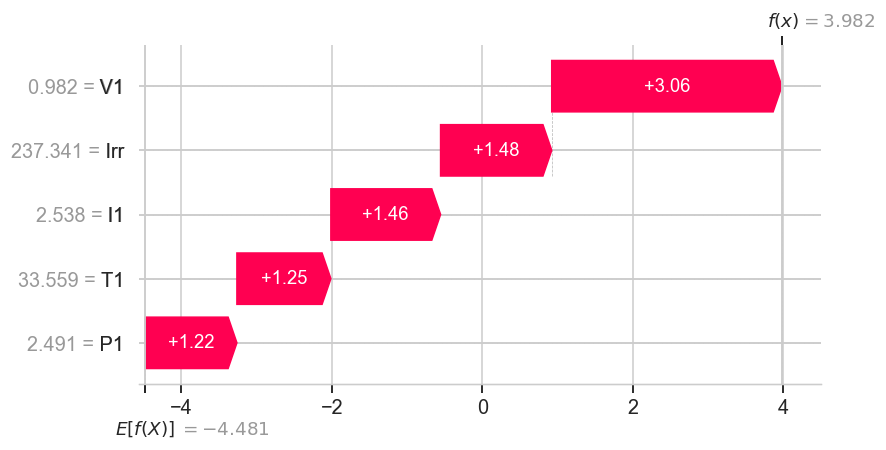


🔍 Scenario B: Diagnosing Healthy Normal String (Sample #0)
   Sensor Readings: {'I1': 0.0574999999999992, 'V1': 5.198437500000001, 'T1': 37.90265352903685, 'P1': 0.2989101562499959, 'Irr': 710.0}
   Model Prediction: Normal (Confidence = 99.99%)



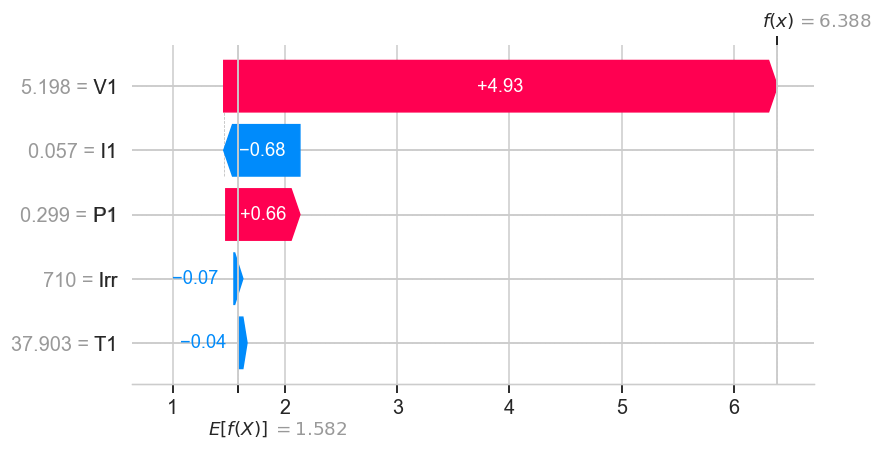

In [9]:
# ==============================================================================
# Step 5.3: Local Diagnostics on Specific Real-World Scenarios
# ==============================================================================

# Find index of a true Short Circuit instance in the sample
sc_indices = np.where(y_shap == 1)[0]
sc_idx = sc_indices[0] if len(sc_indices) > 0 else 0

# Find index of a true Normal instance
normal_indices = np.where(y_shap == 0)[0]
normal_idx = normal_indices[0] if len(normal_indices) > 0 else 1

print(f"🔍 Scenario A: Diagnosing Short Circuit Case (Sample #{sc_idx})")
print("   Sensor Readings:", X_shap.iloc[sc_idx].to_dict())
pred_probs_sc = model.predict_proba(X_shap.iloc[[sc_idx]])[0]
print(f"   Model Prediction: {class_names[np.argmax(pred_probs_sc)]} (Confidence = {np.max(pred_probs_sc):.2%})\n")

# Waterfall Plot for Short Circuit
plt.figure(figsize=(9, 4))
shap.plots.waterfall(
    shap_values[sc_idx, :, 1], 
    max_display=6, 
    show=True
)

print(f"\n🔍 Scenario B: Diagnosing Healthy Normal String (Sample #{normal_idx})")
print("   Sensor Readings:", X_shap.iloc[normal_idx].to_dict())
pred_probs_norm = model.predict_proba(X_shap.iloc[[normal_idx]])[0]
print(f"   Model Prediction: {class_names[np.argmax(pred_probs_norm)]} (Confidence = {np.max(pred_probs_norm):.2%})\n")

# Waterfall Plot for Normal State
plt.figure(figsize=(9, 4))
shap.plots.waterfall(
    shap_values[normal_idx, :, 0], 
    max_display=6, 
    show=True
)


---
### 5.4 SHAP Decision Plot
#### تتبع مسار القرارات المتتابعة لمجموعة من العينات (Decision Trajectories)

Decision plots show how complex models make decisions sample-by-sample. Each line represents a single telemetry reading, tracing how each feature consecutively adds or subtracts from the base value until arriving at the model's final confidence score.


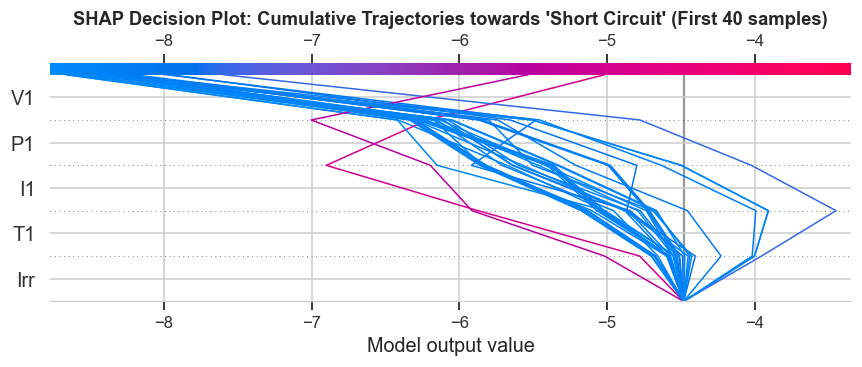

In [10]:
# ==============================================================================
# Step 5.4: Multi-Sample Decision Plot
# ==============================================================================
n_decision_samples = min(40, len(X_shap))
base_val_sc = explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value

plt.figure(figsize=(10, 6))
shap.decision_plot(
    base_val_sc, 
    shap_values.values[:n_decision_samples, :, 1], 
    X_shap.iloc[:n_decision_samples], 
    feature_names=features,
    highlight=np.where(y_shap.iloc[:n_decision_samples] == 1)[0],
    show=False
)
plt.title(f"SHAP Decision Plot: Cumulative Trajectories towards 'Short Circuit' (First {n_decision_samples} samples)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


---
## 6. Level 4: LIME (Local Interpretable Model-agnostic Explanations)
### التفسير المحلي بنموذج بديل خطي وقواعد قرار مقروءة للبشر

**LIME** tests what happens to the model's predictions when we perturb the inputs around a specific sample. It then fits a simple, interpretable linear model (such as a Ridge or Lasso regressor) weighted by proximity to the instance.

**Primary Advantage**: LIME produces intuitive, **rule-based thresholds** (e.g. $V_1 \le 0.04\text{ V}$ and $I_1 > 7.50\text{ A}$), which can be directly converted into hard rules for SCADA alarm systems.


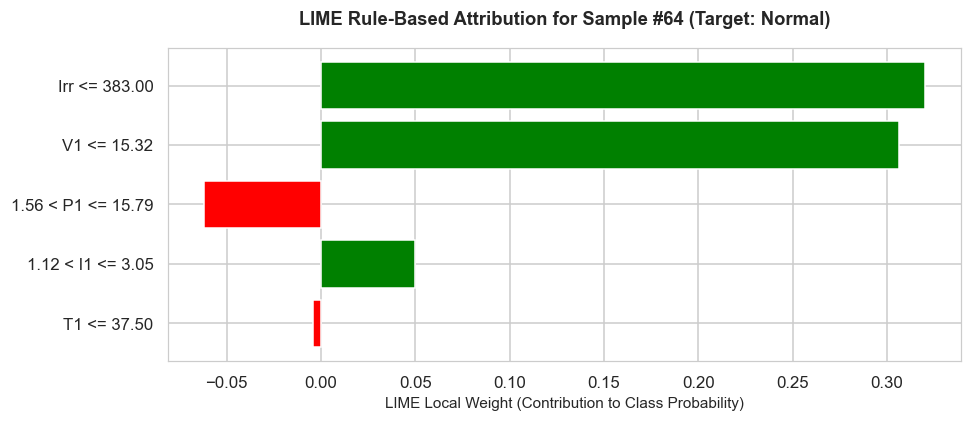

📋 Human-Readable Decision Rules Extracted by LIME for Normal:
   • Rule [Irr <= 383.00            ] : Weight = +0.3204 (Increases Risk (+))
   • Rule [V1 <= 15.32              ] : Weight = +0.3063 (Increases Risk (+))
   • Rule [1.56 < P1 <= 15.79       ] : Weight = -0.0620 (Decreases Risk (-))
   • Rule [1.12 < I1 <= 3.05        ] : Weight = +0.0500 (Increases Risk (+))
   • Rule [T1 <= 37.50              ] : Weight = -0.0045 (Decreases Risk (-))


In [11]:
# ==============================================================================
# Step 6: LIME Local Tabular Explainer
# ==============================================================================
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=features,
    class_names=class_names,
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Explain the Short Circuit fault instance
lime_exp = lime_explainer.explain_instance(
    data_row=X_shap.iloc[sc_idx].values,
    predict_fn=model.predict_proba,
    num_features=5,
    top_labels=2
)

# Plot LIME explanation for the top predicted class
top_label = lime_exp.top_labels[0]
fig = lime_exp.as_pyplot_figure(label=top_label)
fig.set_size_inches(9, 4)
plt.title(f"LIME Rule-Based Attribution for Sample #{sc_idx} (Target: {class_names[top_label]})", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("LIME Local Weight (Contribution to Class Probability)", fontsize=10)
plt.tight_layout()
plt.show()

print(f"📋 Human-Readable Decision Rules Extracted by LIME for {class_names[top_label]}:")
for rule, weight in lime_exp.as_list(label=top_label):
    direction = "Increases Risk (+)" if weight > 0 else "Decreases Risk (-)"
    print(f"   • Rule [{rule:<25}] : Weight = {weight:+.4f} ({direction})")


---
## 7. Level 5: Partial Dependence Plots (PDP) & 2D Interactions
### منحنيات الاعتماد الجزئي الهامشية وحدود الأعطال في الفضاء التشغيلي

**Partial Dependence Plots (PDP)** show the marginal effect that one or two features have on the predicted outcome, averaging out the effects of all other features:
* **1D PDP**: Shows whether increasing current or voltage monotonically increases or decreases fault likelihood.
* **2D PDP**: Creates a contour map illustrating the multi-variable boundary envelope in the $I_1 - V_1$ operational plane.


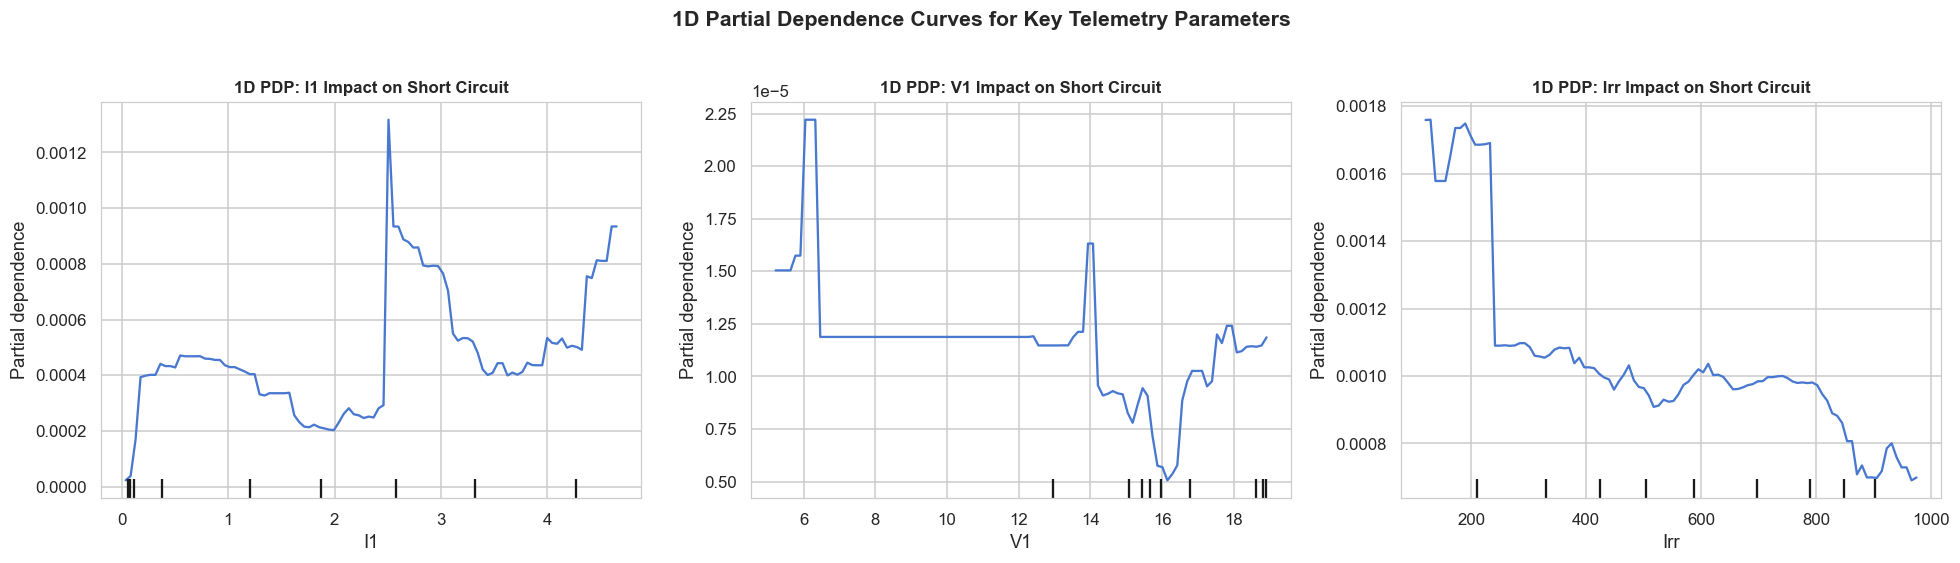

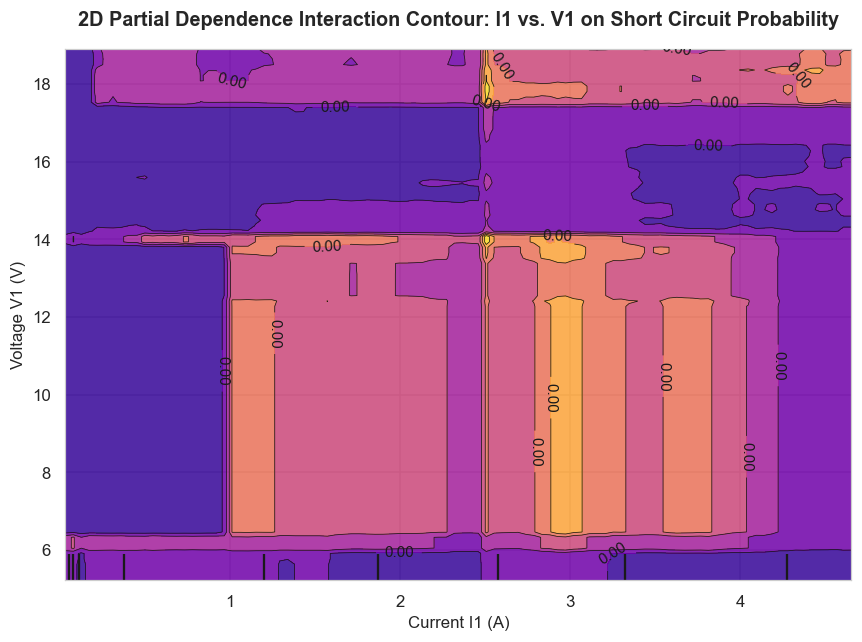

In [12]:
# ==============================================================================
# Step 7: Partial Dependence Plots (1D Curves & 2D Interaction Contour)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1D PDP for Current (I1), Voltage (V1), and Irradiance (Irr) on Short Circuit (Class 1)
pdp_features = [["I1"], ["V1"], ["Irr"]]
for i, feat in enumerate(pdp_features):
    PartialDependenceDisplay.from_estimator(
        estimator=model,
        X=X_shap,
        features=feat,
        target=1, # Short Circuit
        ax=axes[i]
    )
    axes[i].set_title(f"1D PDP: {feat[0]} Impact on Short Circuit", fontsize=11, fontweight='bold')
    axes[i].set_ylabel("Partial Dependence (Class 1)", fontsize=10)

plt.suptitle("1D Partial Dependence Curves for Key Telemetry Parameters", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 2D Interaction PDP between Current (I1) and Voltage (V1)
fig, ax = plt.subplots(figsize=(8, 6))
PartialDependenceDisplay.from_estimator(
    estimator=model,
    X=X_shap,
    features=[("I1", "V1")],
    target=1, # Short Circuit
    ax=ax,
    contour_kw={"cmap": "plasma", "alpha": 0.85}
)
plt.title("2D Partial Dependence Interaction Contour: I1 vs. V1 on Short Circuit Probability", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Current I1 (A)", fontsize=11)
plt.ylabel("Voltage V1 (V)", fontsize=11)
plt.tight_layout()
plt.show()


---
## 8. Summary & Comparative Synthesis (Engineering Takeaways)
### مقارنة شاملة بين تقنيات XAI وتوصيات التشغيل الصناعي

| XAI Technique | Underlying Basis | Scope | Speed | Faithfulness | Best Practical Use in PV Systems |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **XGBoost Gain** | Training loss reduction | Global | Instantaneous ($pprox 0$s) | Model-Specific | Rapid feature pruning during model development |
| **Permutation Importance** | Shuffling on test set | Global | Fast ($pprox 1-3$s) | Model-Agnostic | Validating generalization on unseen sensor feeds |
| **SHAP Summary / Bar** | Game Theory Shapley values | Global | Very Fast (TreeSHAP) | High / Exact | Verifying alignment with solar physics ($P=I \cdot V$) |
| **SHAP Waterfall / Force** | Additive local attribution | Local | Real-Time ($<10$ms) | Very High | Automated root cause diagnostics on SCADA alerts |
| **LIME Tabular** | Local linear surrogate | Local | Moderate ($pprox 100$ms) | Approximate | Generating rule thresholds for physical alarm systems |
| **Partial Dependence (PDP)** | Marginal expectations | Global | Moderate | High | Mapping operating envelopes & non-linear limits |


In [13]:
# ==============================================================================
# Step 8: Production-Ready Diagnostic Inference & Automated XAI Report
# ==============================================================================
def diagnose_pv_telemetry(telemetry_dict, print_report=True):
    """
    End-to-end operational diagnostic function:
    Takes raw sensor readings, runs XGBoost classification, calculates SHAP
    attributions, and prints an actionable root-cause report.
    """
    # Build single-row DataFrame
    input_df = pd.DataFrame([telemetry_dict])[features]
    
    # Model inference
    probs = model.predict_proba(input_df)[0]
    pred_class_idx = int(np.argmax(probs))
    pred_class_name = class_names[pred_class_idx]
    confidence = probs[pred_class_idx]
    
    # Local SHAP calculation
    shap_inst = explainer(input_df)
    class_shaps = shap_inst.values[0, :, pred_class_idx]
    
    # Sort features by impact
    impact_order = np.argsort(np.abs(class_shaps))[::-1]
    
    if print_report:
        status_symbol = "🟢" if pred_class_idx == 0 else "🔴"
        print("=" * 65)
        print(f"{status_symbol} TELEMETRY DIAGNOSTIC REPORT | {pred_class_name.upper()}")
        print("=" * 65)
        print(f"🎯 Diagnosis      : {pred_class_name}")
        print(f"📊 Confidence     : {confidence:.2%}")
        print("⚡ Sensor Input   : " + ", ".join([f"{k}={v:.2f}" for k, v in telemetry_dict.items()]))
        print("-" * 65)
        print("🔍 Top Root-Cause Drivers (SHAP Attribution):")
        for rank, f_idx in enumerate(impact_order[:3], start=1):
            f_name = features[f_idx]
            f_val = telemetry_dict[f_name]
            f_shap = class_shaps[f_idx]
            direction = "🔺 Pushing Towards Fault" if f_shap > 0 else "🔻 Mitigating Factor"
            print(f"   {rank}. {f_name:<4} = {f_val:<7.2f} | SHAP: {f_shap:+.4f} ({direction})")
        print("=" * 65 + "\n")
    
    return {
        "predicted_class": pred_class_name,
        "confidence": confidence,
        "all_probabilities": {name: float(p) for name, p in zip(class_names, probs)},
        "top_drivers": [(features[i], float(class_shaps[i])) for i in impact_order]
    }

# Test on 3 live simulated telemetry scenarios:
test_scenarios = [
    {"I1": 7.85, "V1": 0.03, "T1": 45.0, "P1": 0.24, "Irr": 950.0},  # Suspected Short Circuit
    {"I1": 0.01, "V1": 21.20, "T1": 42.0, "P1": 0.21, "Irr": 910.0},  # Suspected Open Circuit
    {"I1": 5.80, "V1": 17.50, "T1": 35.0, "P1": 101.5, "Irr": 750.0}   # Normal Operation
]

for scenario in test_scenarios:
    diagnose_pv_telemetry(scenario)


🟢 TELEMETRY DIAGNOSTIC REPORT | NORMAL
🎯 Diagnosis      : Normal
📊 Confidence     : 69.49%
⚡ Sensor Input   : I1=7.85, V1=0.03, T1=45.00, P1=0.24, Irr=950.00
-----------------------------------------------------------------
🔍 Top Root-Cause Drivers (SHAP Attribution):
   1. V1   = 0.03    | SHAP: +2.6773 (🔺 Pushing Towards Fault)
   2. Irr  = 950.00  | SHAP: -1.2127 (🔻 Mitigating Factor)
   3. I1   = 7.85    | SHAP: +0.4317 (🔺 Pushing Towards Fault)

🔴 TELEMETRY DIAGNOSTIC REPORT | OPEN CIRCUIT
🎯 Diagnosis      : Open Circuit
📊 Confidence     : 99.99%
⚡ Sensor Input   : I1=0.01, V1=21.20, T1=42.00, P1=0.21, Irr=910.00
-----------------------------------------------------------------
🔍 Top Root-Cause Drivers (SHAP Attribution):
   1. V1   = 21.20   | SHAP: +6.0053 (🔺 Pushing Towards Fault)
   2. I1   = 0.01    | SHAP: +2.2967 (🔺 Pushing Towards Fault)
   3. Irr  = 910.00  | SHAP: -0.0910 (🔻 Mitigating Factor)

🟢 TELEMETRY DIAGNOSTIC REPORT | NORMAL
🎯 Diagnosis      : Normal
📊 Confidence